# Gnod — Clustering songs by their sound

**Goal.** Group the ~1,365 songs from the collection notebook into clusters of
similar-*sounding* tracks, using only their audio features. These clusters are
the engine of the recommender: if a user likes a song, we suggest other songs
from its cluster.

**Approach.**
1. Scale the audio features (clustering uses distances).
2. Choose the number of clusters `k` with the elbow method and three metrics.
3. Compare K-Means, agglomerative clustering and DBSCAN.
4. Interpret the chosen clusters and check them against the genre labels.
5. Build a simple recommender and save the labelled dataset for the app.

The `genre` column is kept only to **check** the clusters at the end (an answer
key); it is never used to fit the models.


## Setup

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

## Load the data

In [16]:
df = pd.read_csv("../data/gnod_songs_deezer.csv")
print(df.shape)
df.head()

(1365, 18)


,isrc,genre,song,artist,id,href,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,is_hot100
0,SEVHC0007060,rock,Hate To Say I Told You So,The Hives,20j7B6mL9gnNvG3ic6Vwh5,https://open.spotify.com/track/20j7B6mL9gnNvG3...,0.00126,0.459,0.931,0.008810,5.0,0.4120,-5.024,1.0,0.0612,135.826,0.419,False
1,GBFFP0300052,rock,Mr. Brightside,The Killers,3FDtyqVmoFR1pk4Ql7CwE3,https://open.spotify.com/track/3FDtyqVmoFR1pk4...,0.00119,0.354,0.918,0.000000,1.0,0.0971,-4.360,1.0,0.0747,148.112,0.240,False
2,GBBQY9700008,rock,Stand By Me,Oasis,2gANywSFYF58YFMPdDSAjC,https://open.spotify.com/track/2gANywSFYF58YFM...,0.01420,0.214,0.828,0.000002,7.0,0.1610,-2.660,1.0,0.0383,169.876,0.388,False
3,NLA320581343,rock,Rockstar,Nickelback,2sDA661pP0j8o0zeorMeng,https://open.spotify.com/track/2sDA661pP0j8o0z...,0.05840,0.622,0.850,0.000000,0.0,0.3230,-6.207,1.0,0.0374,144.071,0.745,False
4,GBCEL1300363,rock,R U Mine?,Arctic Monkeys,2AT8iROs4FQueDv2c8q2KE,https://open.spotify.com/track/2AT8iROs4FQueDv...,0.00616,0.288,0.758,0.000000,6.0,0.3030,-5.692,0.0,0.0371,97.094,0.619,False


## Choose and scale the features

We use the 9 continuous audio features. `key` and `mode` are numbers but really
categories (a musical key, major/minor), so the distance between them is
meaningless and they are left out.

The features live on very different scales — `tempo` goes up to ~200 and
`loudness` down to -46, while the others are between 0 and 1. Clustering is based
on distances, so without scaling `tempo` and `loudness` would dominate.
`StandardScaler` gives every feature mean 0 and standard deviation 1.

In [17]:
features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# check: every feature now has mean ~0 and std ~1
print("mean:", X_scaled.mean(axis=0).round(2))
print("std: ", X_scaled.std(axis=0).round(2))

mean: [ 0.  0.  0. -0.  0. -0.  0.  0. -0.]
std:  [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Choosing k — elbow and silhouette

K-Means needs the number of clusters `k` up front. Two tools help pick it:
- **Inertia** (elbow method): how tight the clusters are. It always falls as `k`
  grows, so we look for the "elbow" where adding clusters stops helping much.
- **Silhouette score**: how separated the clusters are (higher is better).

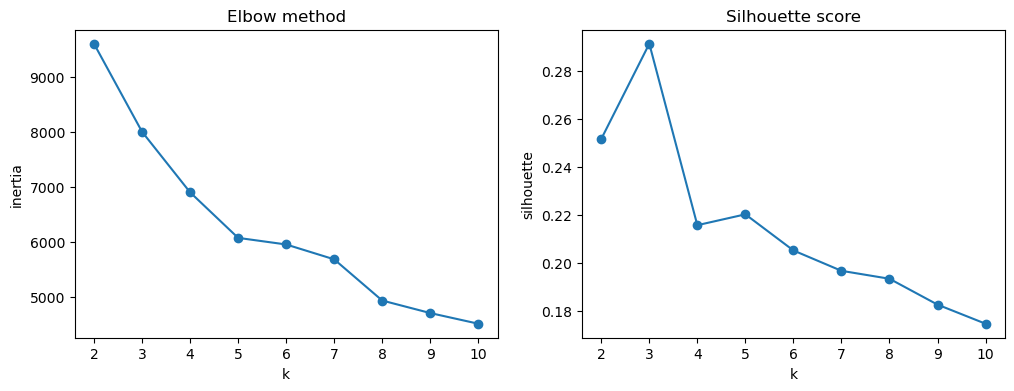

In [18]:
inertias = []
silhouettes = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, model.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(k_values, inertias, marker="o")
ax1.set(title="Elbow method", xlabel="k", ylabel="inertia")
ax2.plot(k_values, silhouettes, marker="o")
ax2.set(title="Silhouette score", xlabel="k", ylabel="silhouette")
plt.show()

The elbow falls smoothly with no sharp bend, and the silhouette is highest at
the smallest k and then roughly flat — real music does not split into cleanly
separated groups, so the metrics do not hand us a single "best" k. We look at a
couple more metrics below, then choose k on practical grounds.


## Confirming k with three metrics

Each metric measures "good clusters" slightly differently, so we look at three:

| Metric | Better |
|---|---|
| Silhouette | higher |
| Calinski-Harabasz | higher |
| Davies-Bouldin | lower |

In [19]:
def cluster_metrics(X, labels):
    """The three internal metrics, computed without DBSCAN noise points (-1)."""
    kept = labels != -1
    X, labels = X[kept], labels[kept]
    return {"silhouette": silhouette_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels),
            "davies_bouldin": davies_bouldin_score(X, labels)}


rows = [cluster_metrics(X_scaled, KMeans(n_clusters=k, random_state=42).fit_predict(X_scaled))
        for k in k_values]
metrics_df = pd.DataFrame(rows, index=k_values)
metrics_df.round(3)

,silhouette,calinski_harabasz,davies_bouldin
2,0.252,379.945,1.799
3,0.291,364.155,1.380
4,0.216,353.754,1.511
5,0.220,347.807,1.431
6,0.205,289.150,1.521
7,0.197,263.021,1.577
8,0.193,289.024,1.470
9,0.183,273.158,1.488
10,0.175,259.559,1.540


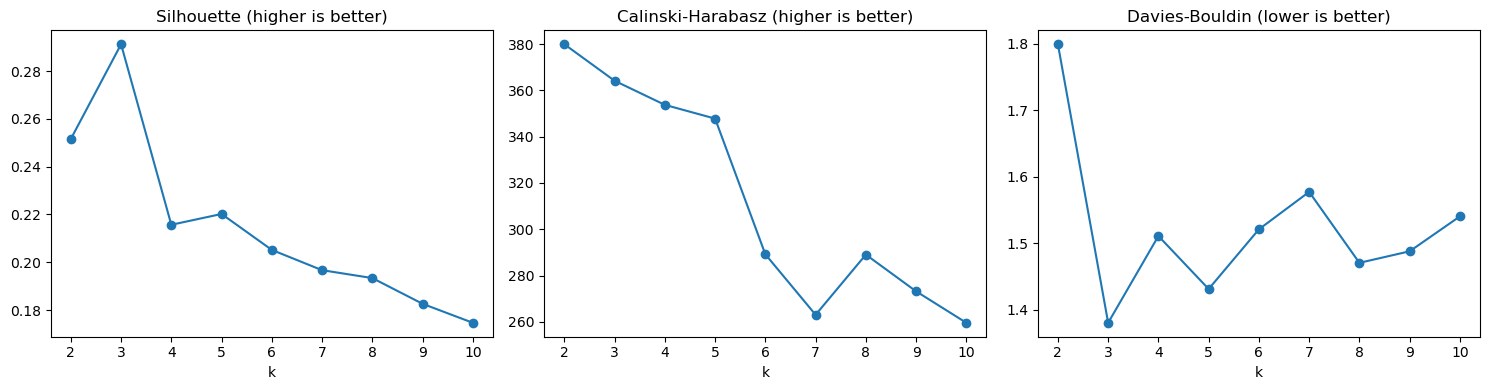

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(k_values, metrics_df["silhouette"], marker="o")
axes[0].set(title="Silhouette (higher is better)", xlabel="k")
axes[1].plot(k_values, metrics_df["calinski_harabasz"], marker="o")
axes[1].set(title="Calinski-Harabasz (higher is better)", xlabel="k")
axes[2].plot(k_values, metrics_df["davies_bouldin"], marker="o")
axes[2].set(title="Davies-Bouldin (lower is better)", xlabel="k")
plt.tight_layout()
plt.show()

The metrics actually lean toward a **small** number of clusters (k=3 scores best
on silhouette and Davies-Bouldin), but 3 groups of ~450 songs are far too broad
to recommend from. The scores barely change from k=5 to k=8, so there is little
penalty for using more clusters. We choose **k=7**: it gives more specific
"vibes" to recommend from, while K-Means stays balanced with no empty or giant
clusters. The real test of this choice is the hit-rate evaluation (see
`gnod_evaluation.ipynb`).


## Comparing the models at k=7

K-Means, three agglomerative linkages and DBSCAN, side by side. We report the
silhouette **and** the cluster sizes and noise: a model can score well by putting
almost every song in one cluster (useless for recommending) or, for DBSCAN, by
labelling many songs as noise.

In [21]:
K = 7
kmeans_labels = KMeans(n_clusters=K, random_state=42).fit_predict(X_scaled)

agglo_labels = {}
for linkage in ["ward", "complete", "average"]:
    agglo_labels[linkage] = AgglomerativeClustering(n_clusters=K, linkage=linkage).fit_predict(X_scaled)

dbscan_labels = DBSCAN(eps=1.4, min_samples=5).fit_predict(X_scaled)

In [22]:
def cluster_sizes(labels):
    """Biggest and smallest cluster size, ignoring DBSCAN noise (-1)."""
    sizes = np.bincount(labels[labels != -1])
    return sizes.max(), sizes.min()


all_labels = {"K-Means": kmeans_labels,
              "Agglo-ward": agglo_labels["ward"],
              "Agglo-complete": agglo_labels["complete"],
              "Agglo-average": agglo_labels["average"],
              "DBSCAN": dbscan_labels}

rows = []
for name, labels in all_labels.items():
    not_noise = labels != -1
    biggest, smallest = cluster_sizes(labels)
    rows.append({"model": name,
                 "n_clusters": len(set(labels) - {-1}),
                 "silhouette": round(silhouette_score(X_scaled[not_noise], labels[not_noise]), 3),
                 "biggest": biggest,
                 "smallest": smallest,
                 "noise_%": round(np.mean(labels == -1) * 100)})

comparison = pd.DataFrame(rows)
comparison

,model,n_clusters,silhouette,biggest,smallest,noise_%
0,K-Means,7,0.197,447,40,0
1,Agglo-ward,7,0.196,391,30,0
2,Agglo-complete,7,0.162,617,20,0
3,Agglo-average,7,0.232,989,3,0
4,DBSCAN,2,0.375,1074,83,15


**Reading the table.** The agglomerative linkages score well only by dumping
almost every song into a single cluster, and DBSCAN labels ~15% of songs as
noise — both useless for recommending. **K-Means** keeps the clusters balanced
with no noise, so it is the model we use.


## Interpreting the clusters

Fit the final K-Means, attach the labels, and describe each cluster by its
average feature values (on the original, unscaled scale, so the numbers are
readable).

In [23]:
df["cluster"] = kmeans_labels
df.groupby("cluster")[features].mean().round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.75,0.68,-6.97,0.09,0.19,0.05,0.15,0.74,111.07
1,0.47,0.82,-5.32,0.07,0.07,0.02,0.26,0.47,135.82
2,0.65,0.60,-11.27,0.90,0.81,0.00,0.69,0.63,88.65
3,0.54,0.29,-15.56,0.08,0.69,0.84,0.14,0.32,108.86
4,0.56,0.41,-9.29,0.06,0.62,0.04,0.21,0.38,103.88
5,0.66,0.54,-11.70,0.86,0.73,0.00,0.29,0.62,101.38
6,0.53,0.55,-8.77,0.10,0.48,0.12,0.18,0.61,165.29


Each cluster has a clear character. From the table above, some clusters stand
out as, for example, high **danceability** and **valence** (upbeat), high
**energy** and **loudness** (loud / intense), or high **acousticness** with low
**energy** (calm / acoustic). (The cluster numbers are arbitrary and can change
between runs.) Now open the answer key and see how the clusters line up with the
genres.


In [24]:
pd.crosstab(df["cluster"], df["genre"])

genre,afrobeat,blues,classical,disco,flamenco,folk,funk,gospel,hip-hop,hot100,latin,pop,punk,reggae,rock,soul,techno
cluster,,,,,,,,,,,,,,,,,
0,5,13,1,50,17,0,42,6,9,11,77,59,10,95,14,37,1
1,2,6,1,2,2,0,2,38,0,14,6,45,78,4,79,7,2
2,0,0,0,0,1,0,39,0,0,0,0,0,0,0,0,0,0
3,0,30,50,0,3,0,1,0,53,0,6,1,0,1,0,3,0
4,0,26,7,3,32,2,1,71,7,7,10,20,0,0,4,54,0
5,0,1,0,0,1,0,61,0,2,0,0,0,0,0,0,0,0
6,0,14,5,1,20,0,4,10,7,2,8,13,4,12,1,32,0


In [25]:
adjusted_rand_score(df["genre"], df["cluster"])

0.14474244253522162

The adjusted Rand index is low (around 0.1–0.15) — and that is expected and desired. The
clusters group songs by **sound**, not by genre, and many genres span several
sounds (gospel appears in almost every cluster). A high score would just mean we
had rediscovered the genre labels, which is not the point: a recommender should
match the *vibe*, not the tag.


## A simple recommender

Given a song, return other songs from the same cluster. A fuzzy match on the
title (`get_close_matches`) handles small typos.

In [26]:
from difflib import get_close_matches


def recommend(song_name, n=5):
    """Recommend n songs from the same cluster as song_name (or suggest close titles)."""
    match = df[df["song"].str.lower() == song_name.lower()]
    if len(match) == 0:
        suggestions = get_close_matches(song_name, df["song"].tolist(), n=3, cutoff=0.4)
        print("Song not found. Did you mean:", suggestions)
        return

    song_cluster = match["cluster"].iloc[0]
    same_cluster = df[(df["cluster"] == song_cluster) & (df["song"].str.lower() != song_name.lower())]
    return same_cluster.sample(min(n, len(same_cluster)))[["song", "artist", "genre"]]

In [27]:
recommend("Torn")

Song not found. Did you mean: ['Tonto', 'soan', 'Tuyo']


The Streamlit app refines this: instead of a random pick from the cluster, it
recommends the songs whose audio features are **closest** to the chosen song. In
the hit-rate test (see `gnod_evaluation.ipynb`) this reaches about a **39%**
same-genre hit rate — roughly **5× better than random** picks from the whole
library, and clearly better than a random pick from the same cluster.


## Save the labelled dataset for the app

In [28]:
df.to_csv("../data/gnod_songs_clustered.csv", index=False)
print("saved:", df.shape)

saved: (1365, 19)
